# 01 — Padronização e Escalonamento na Prática

Teoria: [README.md](README.md). Execute as células em ordem e **altere os parâmetros** para ver o efeito.

**Roteiro**
1. O problema: escalas diferentes distorcem distâncias
2. Comparando os escalonadores (com outliers)
3. Quem precisa de escalonamento? KNN × Árvore
4. Vazamento de dados e `Pipeline`
5. Dados reais: a base PNS do Projeto 2
6. Exercícios

In [1]:
import sys
sys.path.append("..")  # permite importar estudos/utils

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   MaxAbsScaler, PowerTransformer, QuantileTransformer,
                                   OneHotEncoder, OrdinalEncoder)
from sklearn.cluster import KMeans

from utils.graficos import dispersao_clusters

rng = np.random.default_rng(42)
plt.rcParams["figure.dpi"] = 90

## 1. O problema: escalas diferentes distorcem distâncias

Dois grupos de pessoas que se distinguem **pela idade** (jovens × idosos), com renda parecida.
A renda varia em milhares, a idade em dezenas. O que o K-Means encontra?

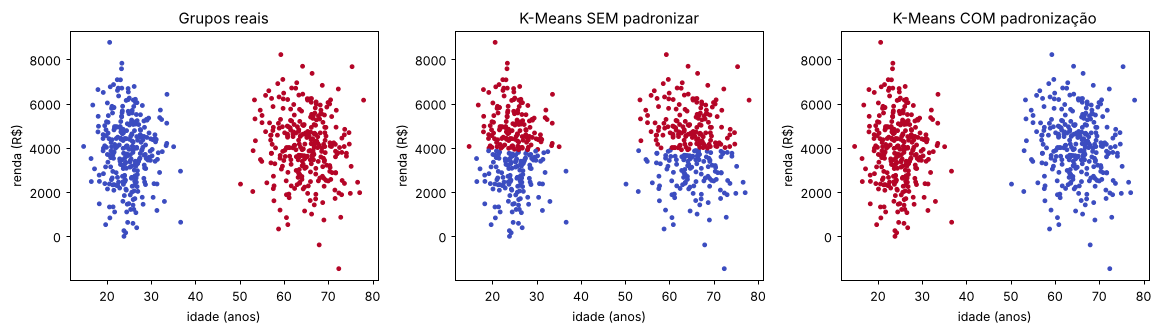

In [2]:
n = 300
idade = np.r_[rng.normal(25, 4, n), rng.normal(65, 5, n)]
renda = np.r_[rng.normal(4000, 1500, n), rng.normal(4000, 1500, n)]
X = np.c_[idade, renda]
grupo_real = np.r_[np.zeros(n), np.ones(n)].astype(int)

km_bruto = KMeans(2, n_init=10, random_state=0).fit_predict(X)
km_padr  = KMeans(2, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(X))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, rot, tit in zip(axs, [grupo_real, km_bruto, km_padr],
                        ["Grupos reais", "K-Means SEM padronizar", "K-Means COM padronização"]):
    ax.scatter(X[:, 0], X[:, 1], c=rot, cmap="coolwarm", s=8)
    ax.set(title=tit, xlabel="idade (anos)", ylabel="renda (R$)")
plt.tight_layout()

Sem padronização, o K-Means corta pela **renda** (maior variância numérica) e ignora a idade.
Após o z-score, as duas variáveis pesam igual e os grupos reais são recuperados.

Vamos medir a concordância com o *Adjusted Rand Index* (1 = perfeito, 0 = acaso):

In [3]:
from sklearn.metrics import adjusted_rand_score as ari
print(f"ARI sem padronizar: {ari(grupo_real, km_bruto):.3f}")
print(f"ARI padronizado:    {ari(grupo_real, km_padr):.3f}")

ARI sem padronizar: 0.001
ARI padronizado:    1.000


## 2. Comparando os escalonadores (com outliers)

Uma variável assimétrica (tipo renda, log-normal) com alguns **outliers** extremos.

In [4]:
x = np.r_[rng.lognormal(mean=7.5, sigma=0.6, size=995), [60000, 75000, 90000, 120000, 150000]].reshape(-1, 1)

escalonadores = {
    "Original": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
    "PowerTransformer (Yeo-Johnson)": PowerTransformer(),
    "QuantileTransformer (normal)": QuantileTransformer(output_distribution="normal", n_quantiles=500),
}

resumo, transformados = [], {}
for nome, esc in escalonadores.items():
    xt = x if esc is None else esc.fit_transform(x)
    transformados[nome] = xt.ravel()
    resumo.append({"escalonador": nome, "média": xt.mean(), "desvio": xt.std(),
                   "mín": xt.min(), "mediana": np.median(xt), "máx": xt.max()})
pd.DataFrame(resumo).set_index("escalonador").round(3)

,média,desvio,mín,mediana,máx
escalonador,,,,,
Original,2554.949,7337.671,290.447,1783.306,150000.000
StandardScaler,-0.000,1.000,-0.309,-0.105,20.094
MinMaxScaler,0.015,0.049,0.000,0.010,1.000
RobustScaler,0.544,5.175,-1.053,-0.000,104.540
MaxAbsScaler,0.017,0.049,0.002,0.012,1.000
PowerTransformer (Yeo-Johnson),0.000,1.000,-3.360,0.097,4.422
QuantileTransformer (normal),-0.000,1.019,-5.199,0.001,5.199


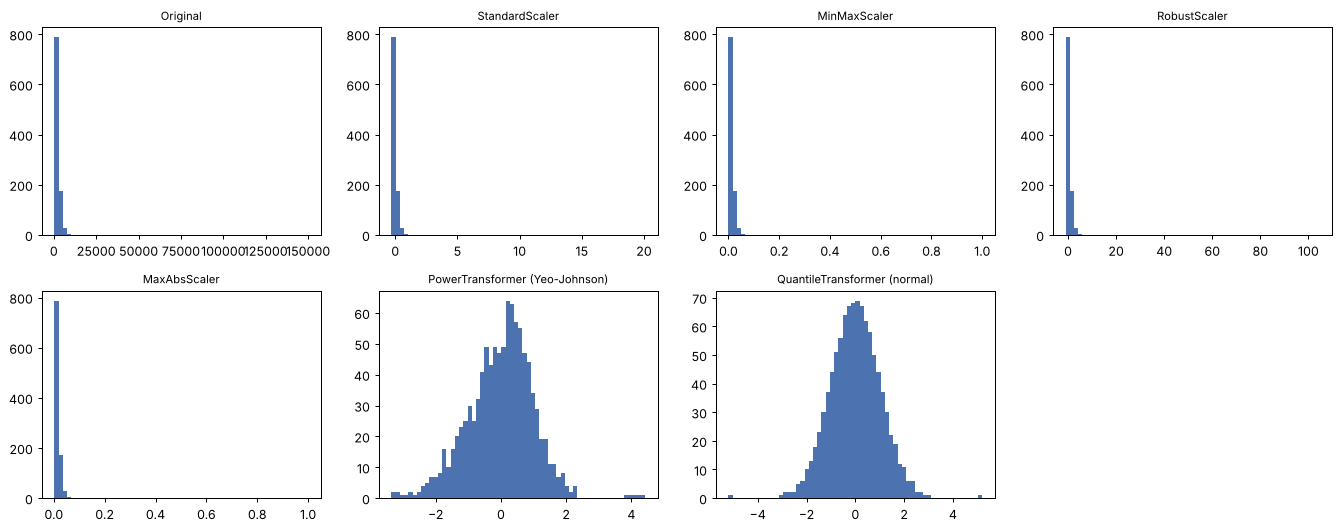

In [5]:
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
for ax, (nome, xt) in zip(axs.ravel(), transformados.items()):
    ax.hist(xt, bins=60, color="#4C72B0")
    ax.set_title(nome, fontsize=9)
axs.ravel()[-1].axis("off")
plt.tight_layout()

**Observe:**
- `MinMaxScaler` e `MaxAbsScaler`: os outliers "esmagam" 99% dos dados perto de 0.
- `StandardScaler`: mesma forma da original, só muda a régua — os outliers inflam o desvio.
- `RobustScaler`: o miolo dos dados fica numa faixa útil; outliers continuam distantes (não são removidos).
- `PowerTransformer` / `QuantileTransformer`: mudam a **forma** da distribuição, deixando-a próxima da normal.

## 3. Quem precisa de escalonamento? KNN × Árvore de decisão

Base *Wine* (embutida no scikit-learn): 13 atributos químicos em escalas muito diferentes
(ex.: prolina ~ 1000, matiz ~ 1).

In [6]:
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

Xw, yw = load_wine(return_X_y=True, as_frame=True)
display(Xw.describe().T[["mean", "std", "min", "max"]].round(2).head(13))

modelos = {
    "KNN sem escalonar": KNeighborsClassifier(),
    "KNN + StandardScaler": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "KNN + MinMaxScaler": make_pipeline(MinMaxScaler(), KNeighborsClassifier()),
    "Árvore sem escalonar": DecisionTreeClassifier(random_state=0),
    "Árvore + StandardScaler": make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=0)),
}
for nome, m in modelos.items():
    acc = cross_val_score(m, Xw, yw, cv=5)
    print(f"{nome:<26} acurácia = {acc.mean():.3f} ± {acc.std():.3f}")

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


KNN sem escalonar          acurácia = 0.691 ± 0.049
KNN + StandardScaler       acurácia = 0.949 ± 0.038
KNN + MinMaxScaler         acurácia = 0.950 ± 0.045
Árvore sem escalonar       acurácia = 0.888 ± 0.040
Árvore + StandardScaler    acurácia = 0.888 ± 0.040


O KNN (baseado em distância) melhora muito com escalonamento. A árvore dá **exatamente** o mesmo
resultado: ela só compara cada atributo com um limiar, e uma transformação monótona não muda a ordem dos valores.
É por isso que nas Listas 3 e 4 (ID3, C4.5, CART, Random Forest) padronizar não fazia diferença.

## 4. Vazamento de dados e `Pipeline`

Errado: ajustar o escalonador em **todos** os dados e depois validar.
Certo: o escalonador é ajustado só no treino de cada dobra — o `Pipeline` faz isso automaticamente.

Nesta base os dois números saem iguais — o vazamento nem sempre muda o resultado. Mas em bases pequenas,
com outliers ou com etapas que aprendem mais dos dados (imputação, seleção de atributos, SMOTE),
ele pode inflar a avaliação. O hábito de usar `Pipeline` evita o problema em todos os casos.

In [7]:
from sklearn.model_selection import KFold

cv = KFold(5, shuffle=True, random_state=1)

# ERRADO: o scaler "viu" os dados de validação
Xw_vazado = StandardScaler().fit_transform(Xw)
errado = cross_val_score(KNeighborsClassifier(), Xw_vazado, yw, cv=cv).mean()

# CERTO
certo = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier()), Xw, yw, cv=cv).mean()
print(f"com vazamento: {errado:.4f}   |   com Pipeline: {certo:.4f}")

com vazamento: 0.9721   |   com Pipeline: 0.9721


## 5. Dados reais: a base PNS do Projeto 2

A mesma base usada no C4.5 e no workflow KNIME (`c45/dados_c45_sembalanceamento_originais.csv`).

In [8]:
from utils.pns import carregar_pns, ordinais_presentes, NUMERICOS, ALVO

pns_bruto = carregar_pns(remover_constantes=False)
constantes = [c for c in pns_bruto.columns if pns_bruto[c].nunique() <= 1]
print("Colunas constantes (sem informação, serão removidas):", constantes)

pns = carregar_pns()
print("Formato:", pns.shape)
pns.head()

Colunas constantes (sem informação, serão removidas): ['VDM001', 'Status_N017']


Formato: (53630, 24)


,A001,C001,C006,C008,C009,C011,D001,M005010,M01601,N010,...,P038,P039,P044,P046,Q00201,VDD004A,VDF004,Status_P02002,Status_P02602,Status_P02801
0,Casa,6.0,Mulher,50-59 anos,Branca,Casado,Sim,Nao,Nenhuma vez,Quase todos os dias,...,Sim,Nao,Nao,Sim,Sim,Fundamental incompleto,Entre 1/4 e 1/2 salario minimo,Incluso na dieta,Nao incluso na dieta,Nao incluso na dieta
1,Casa,8.0,Mulher,39-49 anos,Preta,Solteiro,Sim,Nao,Nenhuma vez,Nenhum dia,...,Sim,Sim,Nao,Nao,Nao,Medio completo,Entre 1/2 e 1 salario minimo,Nao incluso na dieta,Nao incluso na dieta,Incluso na dieta
2,Casa,1.0,Mulher,50-59 anos,Preta,Viuvo,Nao,Nao,Uma vez por mes,Nenhum dia,...,Sim,Sim,Sim,Sim,Nao,Sem instrucao,Entre 1/4 e 1/2 salario minimo,Incluso na dieta,Nao incluso na dieta,Nao incluso na dieta
3,Casa,1.0,Homem,80-89 anos,Parda,Solteiro,Sim,Sem resposta,Nenhuma vez,Quase todos os dias,...,Nao,Nao,Nao,Nao,Sim,Fundamental incompleto,Entre 1/2 e 1 salario minimo,Nao incluso na dieta,Nao incluso na dieta,Nao incluso na dieta
4,Casa,3.0,Mulher,39-49 anos,Parda,Casado,Sim,Nao,Mais de uma vez,Nenhum dia,...,Nao,Sim,Sim,Sim,Nao,Medio completo,Entre 1 e 2 salarios minimos,Incluso na dieta,Nao incluso na dieta,Nao incluso na dieta


### 5.1 A única variável numérica: `C001` (nº de moradores)
Assimétrica à direita, com valores raros até 23. Compare z-score, robusto e log + z-score.

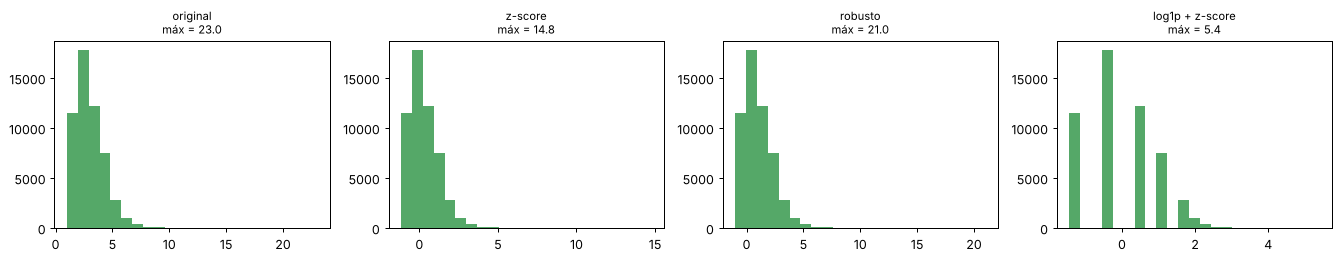

In [9]:
c001 = pns[["C001"]].to_numpy()
versoes = {
    "original": c001,
    "z-score": StandardScaler().fit_transform(c001),
    "robusto": RobustScaler().fit_transform(c001),
    "log1p + z-score": StandardScaler().fit_transform(np.log1p(c001)),
}
fig, axs = plt.subplots(1, 4, figsize=(15, 3))
for ax, (nome, v) in zip(axs, versoes.items()):
    ax.hist(v, bins=23, color="#55A868")
    ax.set_title(f"{nome}\nmáx = {v.max():.1f}", fontsize=9)
plt.tight_layout()

### 5.2 Codificando categorias

- **Ordinais** (faixa etária, escolaridade, renda, frequências) → `OrdinalEncoder` com ordem explícita.
- **Nominais** (cor/raça, estado civil, tipo de domicílio, Sim/Não) → `OneHotEncoder`.
- O alvo `Q00201` fica **fora** do agrupamento (para podermos usá-lo depois na interpretação).

In [10]:
ordinais = ordinais_presentes(pns)
nominais = [c for c in pns.columns if c not in ordinais and c not in NUMERICOS and c != ALVO]
print("Ordinais:", list(ordinais))
print("Nominais:", nominais)

# Exemplo do perigo de codificar nominal como inteiro:
cores_pele = pns[["C009"]].drop_duplicates()
cores_pele["código inteiro (ERRADO p/ distância)"] = OrdinalEncoder().fit_transform(cores_pele[["C009"]]).ravel()
cores_pele

Ordinais: ['C008', 'M01601', 'N010', 'N011', 'N016', 'P02601', 'VDD004A', 'VDF004']
Nominais: ['A001', 'C006', 'C009', 'C011', 'D001', 'M005010', 'P034', 'P038', 'P039', 'P044', 'P046', 'Status_P02002', 'Status_P02602', 'Status_P02801']


,C009,código inteiro (ERRADO p/ distância)
0,Branca,1.0
1,Preta,5.0
3,Parda,4.0
66,Amarela,0.0
185,Indigena,3.0
5614,Ignorado,2.0


### 5.3 One-hot + z-score dá mais peso a categorias raras

O desvio padrão de uma coluna 0/1 com proporção $p$ é $\sqrt{p(1-p)}$. Categorias raras têm
desvio pequeno, então o z-score as **amplia** (ser "1" numa categoria rara vira um valor enorme).

In [11]:
oh = OneHotEncoder(sparse_output=False).fit(pns[["C009"]])
dummies = pd.DataFrame(oh.transform(pns[["C009"]]), columns=oh.get_feature_names_out())
p = dummies.mean()
tabela = pd.DataFrame({"proporção p": p, "desvio √p(1-p)": np.sqrt(p * (1 - p)),
                       "valor z quando = 1": (1 - p) / np.sqrt(p * (1 - p))})
tabela.round(3).sort_values("proporção p")

,proporção p,desvio √p(1-p),valor z quando = 1
C009_Ignorado,0.000,0.011,94.537
C009_Amarela,0.007,0.086,11.550
C009_Indigena,0.007,0.086,11.550
C009_Preta,0.113,0.317,2.795
C009_Branca,0.394,0.489,1.240
C009_Parda,0.477,0.499,1.046


### 5.4 Tudo junto com `ColumnTransformer`

Este pré-processador é reutilizado no notebook [`aplicacao_pns.ipynb`](../02_clusterizacao/aplicacao_pns.ipynb).

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

pre = ColumnTransformer([
    ("num", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), NUMERICOS),
    ("ord", make_pipeline(OrdinalEncoder(categories=list(ordinais.values())), MinMaxScaler()), list(ordinais)),
    ("nom", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), nominais),
])
Xp = pre.fit_transform(pns)
print("Matriz final:", Xp.shape)
pd.DataFrame(Xp, columns=pre.get_feature_names_out()).describe().T[["mean", "std", "min", "max"]].round(2).head(15)

Matriz final: (53630, 45)


,mean,std,min,max
num__C001,0.00,1.00,-1.44,5.4
ord__C008,0.26,0.24,0.00,1.0
ord__M01601,0.28,0.39,0.00,1.0
ord__N010,0.25,0.36,0.00,1.0
ord__N011,0.20,0.31,0.00,1.0
ord__N016,0.14,0.27,0.00,1.0
ord__P02601,0.42,0.18,0.00,1.0
ord__VDD004A,0.41,0.34,0.00,1.0
ord__VDF004,0.45,0.26,0.00,1.0
nom__A001_Apartamento,0.12,0.32,0.00,1.0


Note as decisões (todas discutíveis — e é isso que você deve justificar num relatório):
- numérico: log + z-score (assimetria);
- ordinais: posição em [0, 1] — a distância entre níveis vizinhos é $1/(\text{níveis}-1)$;
- nominais: one-hot **sem** z-score, para cada atributo contribuir com no máximo distância² = 2.

## 6. Exercícios

1. Na seção 1, troque `StandardScaler` por `MinMaxScaler` e `RobustScaler`. O resultado muda? Por quê?
2. Na seção 2, remova os 5 outliers. Quais escalonadores passam a dar resultados parecidos?
3. Na seção 3, teste `RobustScaler` e `PowerTransformer` com o KNN. Algum supera o `StandardScaler`?
4. Na seção 5.4, aplique `StandardScaler` também às colunas one-hot. Quais atributos passam a dominar a distância?
5. Desafio: implemente o z-score "na mão" com NumPy e confira com `StandardScaler` (atenção: ele usa desvio populacional, `ddof=0`).